# Affluence des gares franciliennes : préparation et analyse des données

**Projet Yboost B2, Groupe 1.** Objectif du projet : prédire l'affluence des gares en fonction de la météo et des événements locaux.

Ce notebook couvre les étapes qui précèdent la modélisation :

1. Vérification des sources
2. Harmonisation des fichiers de validations
3. Contrôle qualité
4. Agrégation au niveau gare × jour
5. Enrichissement : calendrier, météo, événements
6. Analyse exploratoire et interprétation
7. Export de la table d'apprentissage

Prérequis : exécuter une fois `python intervention_data/telecharger_validations_2025.py` depuis la racine du projet.

In [1]:
# Masque les avertissements de version des bibliothèques (sans impact sur les résultats)
import warnings
warnings.filterwarnings("ignore")

import json                 # lecture du fichier des jours fériés
import unicodedata          # suppression des accents
from pathlib import Path    # manipulation des chemins, indépendante du système d'exploitation

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Affichage : toutes les colonnes visibles, style de graphique sobre et commun à tout le notebook
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# Racine du projet : fonctionne que le notebook soit lancé depuis la racine ou depuis intervention_data/
RACINE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW = RACINE / "data" / "raw"               # données brutes, jamais modifiées
PROCESSED = RACINE / "data" / "processed"   # données nettoyées produites par ce notebook
PROCESSED.mkdir(exist_ok=True)

## 1. Vérification des sources

Contrôle de la période réellement couverte par les fichiers de validations téléchargés initialement.

In [2]:
# Pour chaque fichier d'origine, on ne lit que la colonne date (lecture rapide)
# et on affiche la première et la dernière date réellement présentes.
for f in sorted((RAW / "validations").glob("*.csv")):
    jours = pd.to_datetime(pd.read_csv(f, sep=";", usecols=["jour"])["jour"])
    print(f"{f.name:42s} {jours.min().date()} -> {jours.max().date()}")

validations_1er_trimestre_2025.csv         2026-01-01 -> 2026-03-31
validations_2eme_trimestre_2025.csv        2026-04-01 -> 2026-06-30
validations_3eme_trimestre_2025.csv        2025-07-01 -> 2025-09-30
validations_4eme_trimestre_2025.csv        2025-10-01 -> 2025-12-31


**Interprétation.** Les fichiers T1 et T2 couvrent 2026, et non 2025. Les jeux de données IDFM par trimestre
sont remplacés chaque année par l'année en cours. La météo et les événements portant sur 2025, la moitié
de l'année n'était pas exploitable.

**Correction.** Les quatre trimestres 2025 sont récupérés depuis l'archive historique IDFM
(`histo-validations-reseau-ferre`) via `telecharger_validations_2025.py`.

Règle à retenir : le nom d'un fichier ne garantit pas son contenu. Contrôler systématiquement les bornes de dates après chargement.

## 2. Harmonisation des quatre trimestres

In [3]:
# Liste des 4 fichiers 2025 produits par le script de téléchargement
FICHIERS = sorted((RAW / "validations_2025").glob("2025_T*.csv"))

# On affiche l'en-tête et la première date de chaque fichier pour repérer les différences de format
for f in FICHIERS:
    with open(f, encoding="utf-8") as fh:
        entete, ligne1 = fh.readline().strip(), fh.readline().strip()
    print(f"{f.name}  {entete}\n{'':13s}première date : {ligne1.split(';')[0]}\n")

2025_T1.csv  JOUR;CODE_STIF_TRNS;CODE_STIF_RES;CODE_STIF_ARRET;LIBELLE_ARRET;ID_ZdC;CATEGORIE_TITRE;NB_VALD
             première date : 2025-01-01 00:00:00

2025_T2.csv  Date;CODE_STIF_TRNS;CODE_STIF_RES;CODE_STIF_ARRET;LIBELLE_ARRET;ID_ZDC;CATEGORIE_TITRE;NB_VALD
             première date : 01/04/2025

2025_T3.csv  JOUR;CODE_STIF_TRNS;CODE_STIF_RES;CODE_STIF_ARRET;ID_ZDC;LIBELLE_ARRET;CATEGORIE_TITRE;NB_VALD
             première date : 01/07/2025

2025_T4.csv  JOUR;CODE_STIF_TRNS;CODE_STIF_RES;CODE_STIF_ARRET;ID_ZDC;LIBELLE_ARRET;CATEGORIE_TITRE;NB_VALD
             première date : 01/10/2025



**Interprétation.** Les quatre fichiers proviennent de la même source mais diffèrent sur quatre points :
nom de la colonne date (`JOUR` / `Date`), format de date (ISO / `JJ/MM/AAAA`), casse (`ID_ZdC` / `ID_ZDC`)
et ordre des colonnes. Une concaténation directe produirait des colonnes décalées et des dates erronées.

On utilise une fonction de lecture unique : lecture en texte, puis conversion explicite de chaque colonne.

In [4]:
def lire_trimestre(chemin: Path) -> pd.DataFrame:
    """Lit un fichier trimestriel et le ramène au format commun."""
    # Tout est lu en texte : aucune conversion automatique, on garde le contrôle des types
    df = pd.read_csv(chemin, sep=";", dtype=str)

    # Noms de colonnes en minuscules (ID_ZdC et ID_ZDC deviennent id_zdc) ; "date" renommée en "jour"
    df.columns = df.columns.str.strip().str.lower()
    df = df.rename(columns={"date": "jour"})

    # On garde les 10 premiers caractères (date sans l'heure).
    # format="mixed" accepte ISO et JJ/MM/AAAA ; dayfirst=True lit 01/04 comme le 1er avril
    df["jour"] = pd.to_datetime(df["jour"].str[:10], format="mixed", dayfirst=True)

    # Conversion en nombres ; une valeur non convertible devient NaN au lieu de provoquer une erreur
    df["nb_vald"] = pd.to_numeric(df["nb_vald"], errors="coerce")
    df["id_zdc"] = pd.to_numeric(df["id_zdc"], errors="coerce")

    df["fichier"] = chemin.stem   # trace du fichier d'origine, utile pour les contrôles
    return df

# Lecture des 4 fichiers puis empilement en une seule table.
# Les colonnes étant alignées par leur nom, l'ordre d'origine n'a plus d'importance.
val = pd.concat([lire_trimestre(f) for f in FICHIERS], ignore_index=True)
print(val.shape)

# Contrôle : bornes de dates et nombre de jours distincts par fichier
val.groupby("fichier")["jour"].agg(["min", "max", "nunique"])

(1892453, 9)


,min,max,nunique
fichier,,,
2025_T1,2025-01-01,2025-03-31,90
2025_T2,2025-04-01,2025-06-30,91
2025_T3,2025-07-01,2025-09-30,92
2025_T4,2025-10-01,2025-12-31,92


**Interprétation.** 1,89 million de lignes, 365 jours consécutifs, sans chevauchement entre fichiers.
Le paramètre `dayfirst=True` est indispensable : sans lui, `01/04/2025` serait interprété comme le 4 janvier,
sans erreur signalée.

## 3. Contrôle qualité

In [5]:
# Nombre de valeurs manquantes, uniquement pour les colonnes concernées
print("Valeurs manquantes :")
print(val.isna().sum()[lambda s: s > 0].to_string(), "\n")

# Liste des valeurs de la colonne texte : permet de repérer doublons et fautes de saisie
val["categorie_titre"].value_counts()

Valeurs manquantes :
id_zdc    1622 



categorie_titre
Forfait Navigo                  284117
Imagine R                       282766
Forfaits courts                 280786
Amethyste                       270264
NON DEFINI                      248620
Autres titres                   244447
Contrat Solidarité Transport    210239
Contrat Solidarite Transport     71214
Name: count, dtype: int64

**Interprétation.** `Contrat Solidarité Transport` et `Contrat Solidarite Transport` désignent la même catégorie
(la version sans accent provient du fichier T4). Sans correction, toute analyse par type de titre serait faussée.
On supprime les accents pour unifier les libellés.

In [6]:
def sans_accent(s: str) -> str:
    """Supprime les accents : 'Solidarité' devient 'Solidarite'."""
    # NFKD sépare chaque lettre de son accent, puis l'encodage ASCII élimine les accents
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().strip()

val["categorie_titre"] = val["categorie_titre"].map(sans_accent)

# Lignes sans identifiant de gare exploitable (manquant ou égal à -1)
inconnus = val[val["id_zdc"].isna() | (val["id_zdc"] <= 0)]
print(f"{len(inconnus)} lignes sans identifiant de gare valide, "
      f"soit {inconnus.nb_vald.sum() / val.nb_vald.sum():.2%} des validations")
inconnus["libelle_arret"].value_counts()

2785 lignes sans identifiant de gare valide, soit 0.15% des validations


libelle_arret
Inconnu            1536
Aéroport d'Orly    1249
Name: count, dtype: int64

**Interprétation.** Ces lignes représentent 0,15 % des validations et ne peuvent être rattachées à aucune gare.
Leur suppression n'a pas d'impact sur l'analyse.

### Identifiant de gare

`id_zdc` identifie la zone de correspondance, c'est-à-dire l'ensemble des quais d'un même lieu (métro, RER, Transilien).
Un même `id_zdc` peut porter plusieurs libellés :

In [7]:
# Suppression des lignes sans gare, puis conversion de l'identifiant en entier
val = val[val["id_zdc"] > 0].copy()
val["id_zdc"] = val["id_zdc"].astype(int)

# Pour chaque identifiant, liste des libellés différents rencontrés
libelles = val.groupby("id_zdc")["libelle_arret"].unique()
print(f"{(libelles.str.len() > 1).sum()} gares ont plusieurs libellés. Exemple :")
print(libelles.loc[71517])   # 71517 = La Défense

36 gares ont plusieurs libellés. Exemple :
['LA DEFENSE' 'DEFENSE' 'DEFENSE RER E']


**Interprétation.** La Défense apparaît sous trois libellés. Un regroupement par `libelle_arret` la découperait
en trois gares distinctes et sous-estimerait sa fréquentation. L'agrégation se fait donc par `id_zdc`.

## 4. Agrégation gare × jour

La variable cible est le nombre total de validations d'une gare sur une journée, toutes catégories de titre confondues.

767 gares | complètes (365 j) : 477 | incomplètes : 290


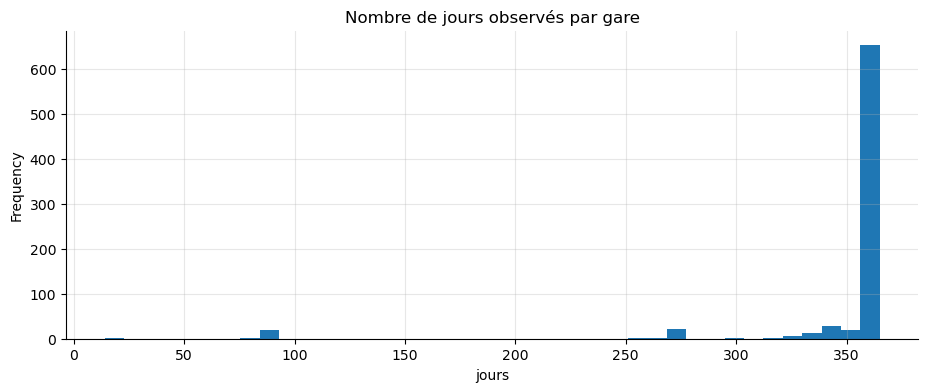

In [8]:
# Somme des validations par gare et par jour (toutes catégories de titre et tous quais confondus)
gare_jour = val.groupby(["id_zdc", "jour"], as_index=False)["nb_vald"].sum()

# Nom affiché de chaque gare : le libellé qui totalise le plus de validations
nom_gare = (val.groupby(["id_zdc", "libelle_arret"])["nb_vald"].sum()
               .reset_index().sort_values("nb_vald")
               .drop_duplicates("id_zdc", keep="last")      # garde la dernière ligne = la plus grande
               .set_index("id_zdc")["libelle_arret"])
gare_jour["gare"] = gare_jour["id_zdc"].map(nom_gare)

# Nombre de jours observés pour chaque gare (365 attendus)
nb_jours = gare_jour.groupby("id_zdc")["jour"].nunique()
print(f"{gare_jour.id_zdc.nunique()} gares | complètes (365 j) : {(nb_jours == 365).sum()} | incomplètes : {(nb_jours < 365).sum()}")
nb_jours.plot.hist(bins=40, title="Nombre de jours observés par gare", xlabel="jours");

**Interprétation.** 290 gares sur 767 n'ont pas 365 jours d'observation. Causes principales : stations ouvertes
en cours d'année (tramways T12, T13), gares à très faible trafic (un jour sans validation n'apparaît pas), fermetures.
On conserve les gares observées au moins 360 jours, ce qui garantit des séries continues pour la modélisation.
Ce choix doit être justifié dans le rapport.

626 gares conservées. Les 15 premières concentrent 23% des validations.


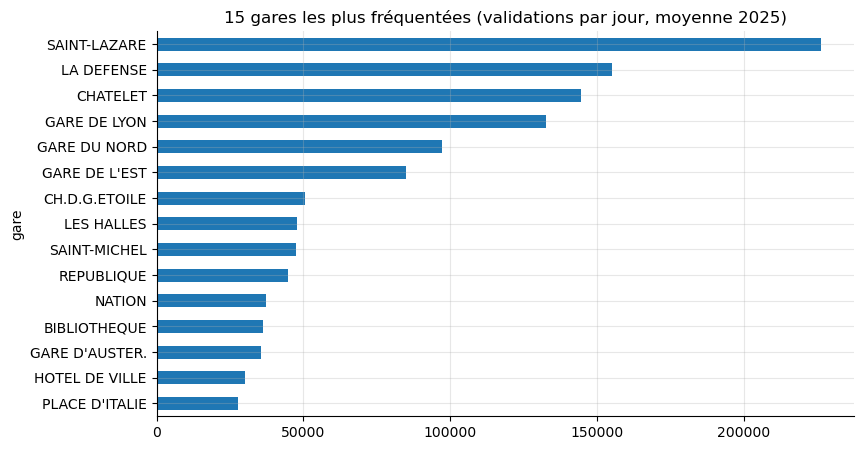

In [9]:
# Filtre : on ne garde que les gares présentes au moins 360 jours sur 365
gares_ok = nb_jours[nb_jours >= 360].index
gare_jour = gare_jour[gare_jour["id_zdc"].isin(gares_ok)].copy()

# Fréquentation moyenne par gare et part des 15 plus grandes dans le total
moy_gare = gare_jour.groupby("gare")["nb_vald"].mean().sort_values()
part_top = moy_gare.tail(15).sum() / moy_gare.sum()
print(f"{len(gares_ok)} gares conservées. Les 15 premières concentrent {part_top:.0%} des validations.")
moy_gare.tail(15).plot.barh(figsize=(9, 5), title="15 gares les plus fréquentées (validations par jour, moyenne 2025)");

**Interprétation.** Les 15 premières gares (sur 626) concentrent près d'un quart des validations ;
Saint-Lazare dépasse 220 000 validations par jour, La Défense, Châtelet et Gare de Lyon plus de 130 000.
Conséquence pour la modélisation : une erreur exprimée en nombre de validations sera dominée par ces grandes gares.
Il est préférable de raisonner en erreur relative (%), ou de modéliser chaque gare séparément.

## 5. Enrichissement

### 5.1 Calendrier

In [10]:
# Une ligne par jour de 2025, puis ajout des variables de calendrier
cal = pd.DataFrame({"jour": pd.date_range("2025-01-01", "2025-12-31")})
cal["jour_semaine"] = cal["jour"].dt.dayofweek          # 0 = lundi, 6 = dimanche
cal["mois"] = cal["jour"].dt.month
cal["weekend"] = (cal["jour_semaine"] >= 5).astype(int) # 1 = samedi ou dimanche

# Jours fériés : le JSON est un dictionnaire {"AAAA-MM-JJ": "nom du jour férié"} couvrant plusieurs années
feries = json.loads((RAW / "jours_feries.json").read_text())
cal["ferie"] = cal["jour"].dt.strftime("%Y-%m-%d").isin(feries).astype(int)

# Vacances scolaires : on marque 1 tous les jours compris entre le début et la fin de chaque période
vac = pd.read_csv(RAW / "calendrier_scolaire.csv", sep=";", parse_dates=["debut", "fin"])
cal["vacances"] = 0
for _, p in vac.iterrows():
    cal.loc[cal["jour"].between(p["debut"], p["fin"]), "vacances"] = 1

print(f"Jours fériés : {cal.ferie.sum()} | jours de vacances scolaires (zone C) : {cal.vacances.sum()}")

Jours fériés : 11 | jours de vacances scolaires (zone C) : 127


### 5.2 Météo (Open-Meteo, Paris)

In [11]:
# Les 3 premières lignes du fichier contiennent les coordonnées de la station, pas les données
meteo = pd.read_csv(RAW / "meteo_open_meteo.csv", skiprows=3)
meteo.columns = ["jour", "temperature", "pluie_mm", "vent_max_kmh"]   # noms courts sans unités
meteo["jour"] = pd.to_datetime(meteo["jour"])

# Indicateur binaire : 1 si au moins 1 mm de pluie (seuil courant pour un "jour de pluie")
meteo["pluie"] = (meteo["pluie_mm"] >= 1).astype(int)
meteo.describe().round(1)

,jour,temperature,pluie_mm,vent_max_kmh,pluie
count,365,365.0,365.0,365.0,365.0
mean,2025-07-01 23:59:59.999999744,12.8,2.0,14.7,0.3
min,2025-01-01 00:00:00,-1.4,0.0,4.1,0.0
25%,2025-04-02 00:00:00,8.1,0.0,11.2,0.0
50%,2025-07-02 00:00:00,12.7,0.1,13.6,0.0
75%,2025-10-01 00:00:00,17.9,2.1,18.3,1.0
max,2025-12-31 00:00:00,32.0,26.8,33.0,1.0
std,NaN,6.8,4.1,5.2,0.5


**Interprétation.** Série complète (365 jours, aucune valeur manquante). Températures de -1 à 32 °C ;
il pleut au moins 1 mm environ un jour sur trois. Une seule station météo est utilisée pour toute l'Île-de-France,
ce qui est une approximation acceptable à l'échelle régionale.

### 5.3 Événements : rattachement aux gares

Le fichier d'événements indique un lieu, pas une gare. Une table de correspondance lieu → gares desservantes est nécessaire.

In [12]:
# Table de correspondance construite manuellement : lieu de l'événement -> gares qui le desservent.
# Les libellés ont été trouvés en cherchant dans les données, par exemple :
# val[val.libelle_arret.str.contains("STADE")].libelle_arret.unique()
LIEU_VERS_GARES = {
    "Stade de France":                 ["STADE DE FRANCE", "PLAINE STADE DE", "ST-DENIS-PTE P"],
    "Parc des Princes":                ["PTE ST-CLOUD", "PTE D'AUTEUIL"],
    "Stade Jean-Bouin":                ["PTE ST-CLOUD", "PTE D'AUTEUIL"],
    "Stade Roland-Garros":             ["PTE D'AUTEUIL", "M.ANGE-AUTEUIL"],
    "Paris La Défense Arena":          ["LA DEFENSE"],
    "Paris Expo Porte de Versailles":  ["PORTE D.VERS.", "BALARD"],
    "Parc des expositions du Bourget": ["BOURGET"],
    "Paris Nord Villepinte":           ["PARC DES EXPO"],
}
# Correspondance libellé -> id_zdc, pour passer du nom de gare à son identifiant
libelle_vers_id = val.drop_duplicates("libelle_arret").set_index("libelle_arret")["id_zdc"]

evts = pd.read_csv(RAW / "evenements_2025.csv", sep=";", parse_dates=["date"])

# 1) on ne garde que les événements dont le lieu est connu
# 2) chaque lieu est remplacé par sa liste de gares, puis explode crée une ligne par gare
evt_gare = (evts[evts["lieu"].isin(LIEU_VERS_GARES)]
            .assign(libelle=lambda d: d["lieu"].map(LIEU_VERS_GARES))
            .explode("libelle"))
evt_gare["id_zdc"] = evt_gare["libelle"].map(libelle_vers_id)

# 3) une seule ligne par gare et par jour (plusieurs événements le même jour sont comptés)
evt_gare = (evt_gare.rename(columns={"date": "jour"})
            .groupby(["id_zdc", "jour"])
            .agg(nb_evenements=("nom", "size"), type_evenement=("type", "first"), nom_evenement=("nom", "first"))
            .reset_index())

# Événements sans lieu fixe (défilés, courses...) : traités à part
non_rattaches = evts.loc[~evts["lieu"].isin(LIEU_VERS_GARES)]
print(f"{len(evts)} événements : {len(evts) - len(non_rattaches)} rattachés à une gare, "
      f"{len(non_rattaches)} diffus (défilés, courses, Fête de la musique...)")

191 événements : 164 rattachés à une gare, 27 diffus (défilés, courses, Fête de la musique...)


**Interprétation.** 86 % des événements sont rattachés à des gares précises. Les événements diffus (14 juillet,
marathon, Fête de la musique) n'ont pas de gare unique : ils sont conservés comme indicateur réseau (`evenement_paris`).

## 6. Table d'analyse (une ligne = une gare, un jour)

In [13]:
# Nombre d'événements diffus par jour (indicateur commun à toutes les gares)
evt_paris = (non_rattaches.groupby("date").size().rename("evenement_paris")
             .reset_index().rename(columns={"date": "jour"}))

# Jointures à gauche : on conserve toutes les lignes gare x jour et on ajoute les informations disponibles
data = (gare_jour
        .merge(cal, on="jour", how="left")                     # calendrier : par jour
        .merge(meteo, on="jour", how="left")                   # météo : par jour
        .merge(evt_gare, on=["id_zdc", "jour"], how="left")    # événements : par gare et par jour
        .merge(evt_paris, on="jour", how="left"))              # événements diffus : par jour

# Les jours sans événement ressortent vides (NaN) après la jointure : on les remplace par 0 / "aucun"
data["nb_evenements"] = data["nb_evenements"].fillna(0).astype(int)
data["evenement"] = (data["nb_evenements"] > 0).astype(int)
data["evenement_paris"] = (data["evenement_paris"].fillna(0) > 0).astype(int)
data["type_evenement"] = data["type_evenement"].fillna("aucun")

# Contrôle : une jointure ne doit jamais ajouter de lignes
assert len(data) == len(gare_jour), "Une jointure a dupliqué des lignes"
print(data.shape)

(228177, 18)


Le contrôle `assert` vérifie qu'aucune jointure n'a dupliqué de lignes. C'est l'erreur la plus fréquente lors
d'un enrichissement (par exemple deux événements le même jour dans la même gare).

## 7. Analyse exploratoire

### 7.1 Évolution annuelle du réseau

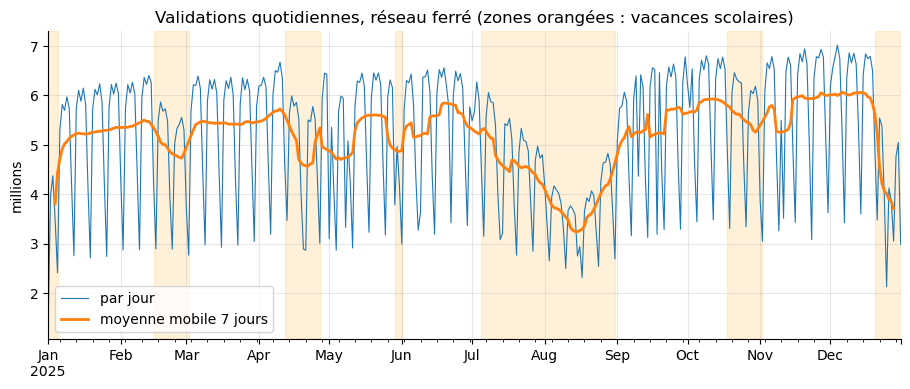

In [14]:
# Total du réseau par jour, complété par le calendrier et la météo
reseau = data.groupby("jour").agg(nb_vald=("nb_vald", "sum")).join(cal.set_index("jour")).join(meteo.set_index("jour"))

# Courbe journalière + moyenne mobile sur 7 jours (lisse le cycle hebdomadaire pour voir la tendance)
ax = (reseau["nb_vald"] / 1e6).plot(lw=0.8, label="par jour")
(reseau["nb_vald"].rolling(7, center=True).mean() / 1e6).plot(ax=ax, lw=2, label="moyenne mobile 7 jours")

# Zones colorées pour les vacances scolaires (bornées à l'année 2025)
for _, p in vac.iterrows():
    ax.axvspan(max(p["debut"], pd.Timestamp("2025-01-01")), min(p["fin"], pd.Timestamp("2025-12-31")), color="orange", alpha=0.15)
ax.set(title="Validations quotidiennes, réseau ferré (zones orangées : vacances scolaires)", ylabel="millions", xlabel="")
ax.legend();

**Interprétation.**
- Le réseau enregistre entre 5 et 7 millions de validations un jour ouvré.
- L'oscillation hebdomadaire est le motif dominant : chaque semaine, l'affluence chute de moitié le dimanche.
- Chaque période de vacances provoque une baisse nette de la moyenne mobile. Le creux d'août est le plus marqué
  (environ -45 % par rapport à juin).
- Le niveau de fin d'année (octobre à décembre) est supérieur à celui du printemps : il existe une tendance,
  qu'une seule année de données ne permet pas de distinguer d'un effet saisonnier.

samedi   : -25% par rapport à un jour de semaine
dimanche : -47% par rapport à un jour de semaine
vacances : -22%
férié    : -42%


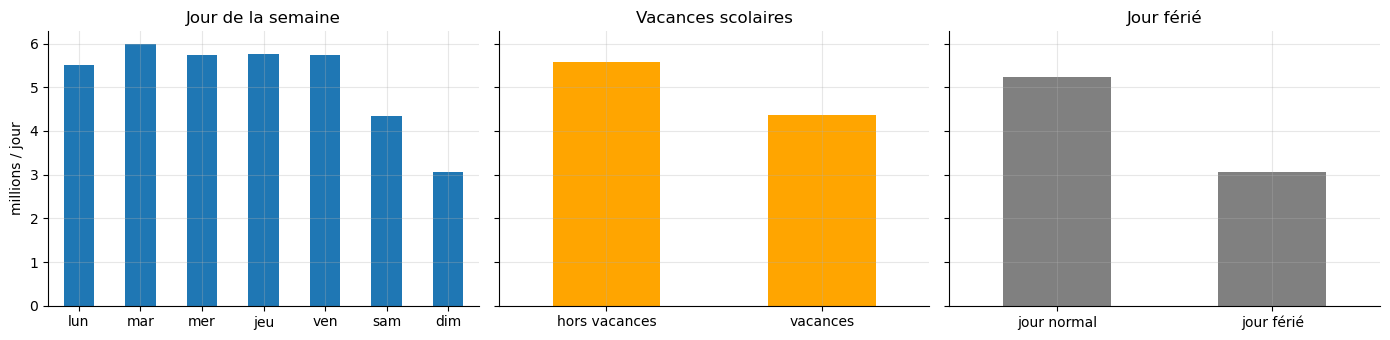

In [15]:
# Moyenne des validations selon trois variables de calendrier
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
jours = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
(reseau.groupby("jour_semaine")["nb_vald"].mean() / 1e6).set_axis(jours).plot.bar(ax=axes[0], title="Jour de la semaine", rot=0)
(reseau.groupby("vacances")["nb_vald"].mean() / 1e6).set_axis(["hors vacances", "vacances"]).plot.bar(ax=axes[1], title="Vacances scolaires", rot=0, color="orange")
(reseau.groupby("ferie")["nb_vald"].mean() / 1e6).set_axis(["jour normal", "jour férié"]).plot.bar(ax=axes[2], title="Jour férié", rot=0, color="grey")
axes[0].set_ylabel("millions / jour")
plt.tight_layout()

# Écarts en pourcentage par rapport à la situation de référence
semaine = reseau.loc[reseau.jour_semaine < 5, "nb_vald"].mean()
for j, nom in [(5, "samedi"), (6, "dimanche")]:
    print(f"{nom:9s}: {reseau.loc[reseau.jour_semaine == j, 'nb_vald'].mean() / semaine - 1:+.0%} par rapport à un jour de semaine")
print(f"vacances : {reseau.loc[reseau.vacances == 1, 'nb_vald'].mean() / reseau.loc[reseau.vacances == 0, 'nb_vald'].mean() - 1:+.0%}")
print(f"férié    : {reseau.loc[reseau.ferie == 1, 'nb_vald'].mean() / reseau.loc[reseau.ferie == 0, 'nb_vald'].mean() - 1:+.0%}")

**Interprétation.**
- Le mardi est le jour le plus chargé, le lundi le moins chargé des jours ouvrés : effet probable du télétravail,
  pris de préférence le lundi et le vendredi.
- Samedi -25 %, dimanche -47 %, vacances -22 %, férié -42 %.
- Le calendrier explique donc l'essentiel de la variabilité. Tout modèle doit intégrer ces variables ;
  sans elles, l'effet de la météo ou des événements ne peut pas être isolé.

### 7.2 Effet de la météo

Comparer directement jours de pluie et jours secs introduit un biais : il pleut davantage en hiver,
période où l'affluence diffère de l'été. Chaque jour est donc comparé à une **affluence attendue** :
la médiane des jours de même type (même jour de semaine, même mois, même statut vacances).

In [16]:
# Affluence attendue : médiane des jours comparables (même jour de semaine, même mois, même statut vacances).
# transform renvoie cette médiane sur chaque ligne, ce qui permet de calculer le ratio jour par jour.
reseau["reference"] = reseau.groupby(["jour_semaine", "mois", "vacances"])["nb_vald"].transform("median")
reseau["ratio"] = reseau["nb_vald"] / reseau["reference"]   # 1 = conforme à l'attendu, 0,9 = -10 %

# Jours fériés exclus (comportement atypique) ; séparation semaine / week-end
normaux = reseau[reseau["ferie"] == 0].copy()
normaux["type_jour"] = np.where(normaux["weekend"] == 1, "week-end", "semaine")

# Trois classes de pluie, définies par des seuils en mm
normaux["classe_pluie"] = pd.cut(normaux["pluie_mm"], [-1, 0.9, 5, 100],
                                 labels=["sec (< 1 mm)", "pluie faible (1-5 mm)", "forte pluie (> 5 mm)"])

# Écart moyen à l'attendu pour chaque combinaison classe de pluie x type de jour
tab = normaux.pivot_table(index="classe_pluie", columns="type_jour", values="ratio", aggfunc="mean")
print("Écart à l'affluence attendue (%) :")
print(((tab - 1) * 100).round(1).to_string())

# Corrélation linéaire entre l'écart à l'attendu et chaque variable météo (0 = aucun lien)
print("\nCorrélation ratio / variables météo :")
print(normaux[["ratio", "temperature", "pluie_mm", "vent_max_kmh"]].corr()["ratio"].drop("ratio").round(2).to_string())

Écart à l'affluence attendue (%) :
type_jour              semaine  week-end
classe_pluie                            
sec (< 1 mm)               0.4       0.7
pluie faible (1-5 mm)     -0.6       1.0
forte pluie (> 5 mm)      -0.4      -1.4

Corrélation ratio / variables météo :
temperature     0.04
pluie_mm       -0.06
vent_max_kmh   -0.01


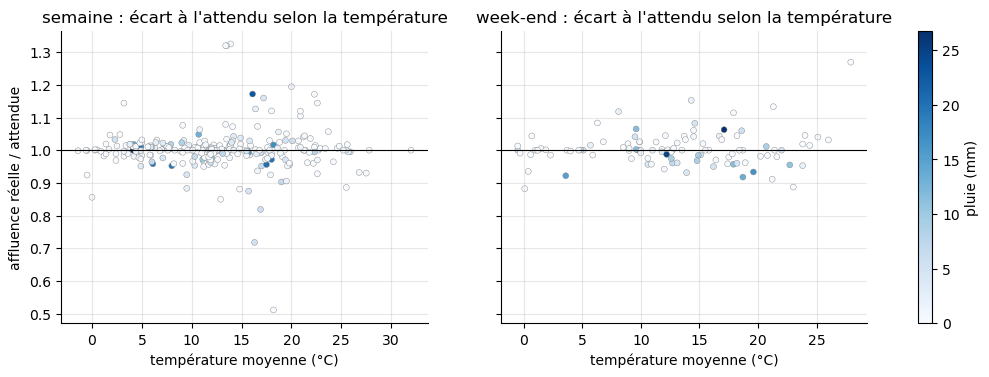

In [17]:
# Nuage de points : chaque point est un jour ; la couleur indique la quantité de pluie
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (type_jour, d) in zip(axes, normaux.groupby("type_jour")):
    sc = ax.scatter(d["temperature"], d["ratio"], c=d["pluie_mm"], cmap="Blues", s=18, edgecolor="grey", lw=0.3)
    ax.axhline(1, color="black", lw=0.8)   # ligne de référence : affluence conforme à l'attendu
    ax.set(title=f"{type_jour} : écart à l'attendu selon la température", xlabel="température moyenne (°C)")
axes[0].set_ylabel("affluence réelle / attendue")
fig.colorbar(sc, ax=axes, label="pluie (mm)");

**Interprétation.**
- À l'échelle du réseau, l'effet de la météo est quasi nul : moins de 2 % d'écart, y compris par forte pluie.
  Les corrélations sont proches de zéro et le nuage de points n'a pas de structure.
- Explication : la majorité des déplacements sont contraints (domicile-travail, études) et ne dépendent pas du temps.
- Le seul signal visible concerne les week-ends de forte pluie (environ -1,5 %), cohérent avec des déplacements de loisirs reportés.

**Conséquence pour le projet.** L'hypothèse « la météo influence l'affluence » n'est pas confirmée au niveau global.
Ce résultat doit figurer dans le rapport. Pour aller plus loin : analyser les gares à vocation de loisirs ou touristique,
les week-ends seuls, ou les épisodes extrêmes (canicule, orages).

### 7.3 Effet des événements

Même méthode, au niveau de chaque gare : référence = médiane de la gare pour le même jour de semaine et le même statut vacances.

Ratio médian (réel / attendu) sur les gares proches d'un lieu d'événement :
evenement
sans événement    1.00
avec événement    1.58


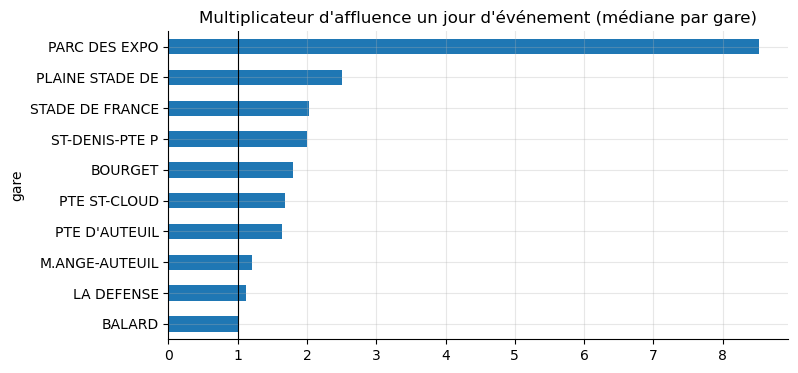

In [18]:
# Affluence attendue propre à chaque gare (même jour de semaine, même statut vacances)
data["reference"] = data.groupby(["id_zdc", "jour_semaine", "vacances"])["nb_vald"].transform("median")
data["ratio"] = data["nb_vald"] / data["reference"]

# Comparaison limitée aux gares proches d'un lieu d'événement : jours avec / sans événement
gares_evt = data[data["id_zdc"].isin(evt_gare["id_zdc"])]
print("Ratio médian (réel / attendu) sur les gares proches d'un lieu d'événement :")
print(gares_evt.groupby("evenement")["ratio"].median().rename({0: "sans événement", 1: "avec événement"}).round(2).to_string())

# Multiplicateur médian par gare, uniquement les jours d'événement
effet_gare = gares_evt[gares_evt["evenement"] == 1].groupby("gare")["ratio"].median().sort_values()
ax = effet_gare.plot.barh(figsize=(8, 4), title="Multiplicateur d'affluence un jour d'événement (médiane par gare)")
ax.axvline(1, color="black", lw=0.8);   # 1 = pas d'effet

**Interprétation.**
- Un jour d'événement, l'affluence des gares concernées est multipliée par 1,6 en médiane. L'effet est nettement
  plus fort que celui de la météo.
- L'effet dépend du rapport entre la taille de l'événement et le trafic habituel de la gare :
  - Parc des Expositions (Villepinte) : x8, gare peu fréquentée en temps normal accueillant des salons de masse ;
  - gares du Stade de France : x2 à x2,5 ;
  - Porte de Saint-Cloud / Porte d'Auteuil (Parc des Princes, Roland-Garros) : x1,7 ;
  - La Défense et Balard : effet nul, l'événement est noyé dans un trafic quotidien très élevé.
- Variables à envisager : capacité du lieu, horaire de l'événement, trafic habituel de la gare.

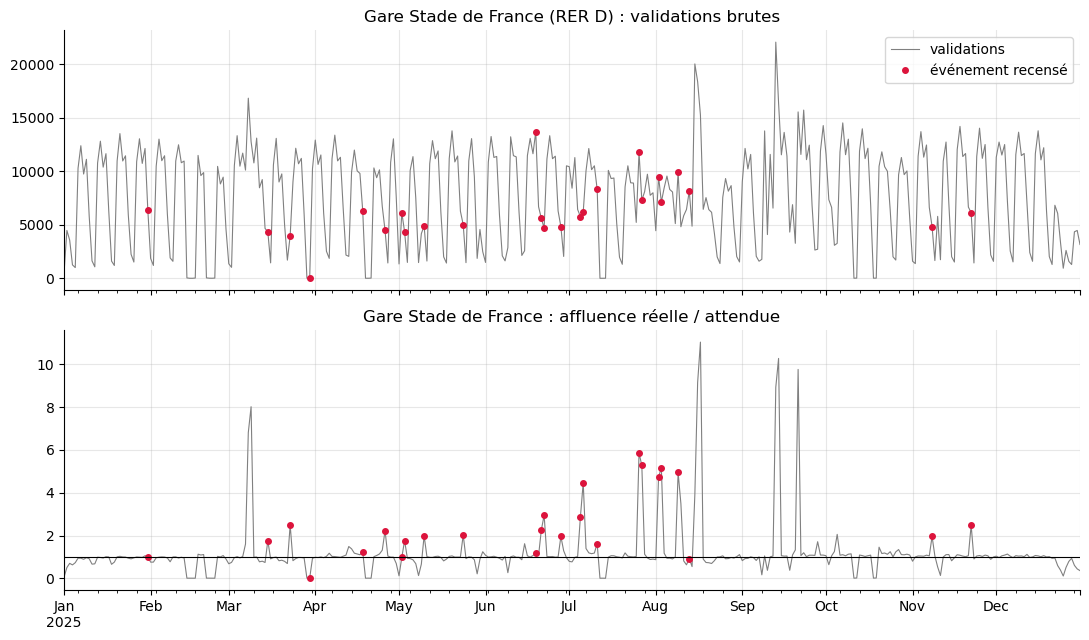

In [19]:
# Étude de cas : gare Stade de France, en valeurs brutes puis en ratio réel / attendu
sdf = data[data["gare"] == "STADE DE FRANCE"].set_index("jour")
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)

# Haut : validations brutes, jours d'événement en rouge
sdf["nb_vald"].plot(ax=axes[0], lw=0.8, color="grey", label="validations")
sdf.loc[sdf["evenement"] == 1, "nb_vald"].plot(ax=axes[0], style="o", color="crimson", ms=4, label="événement recensé")
axes[0].set(title="Gare Stade de France (RER D) : validations brutes")
axes[0].legend()

# Bas : ratio réel / attendu, qui neutralise l'effet du jour de la semaine
sdf["ratio"].plot(ax=axes[1], lw=0.8, color="grey")
sdf.loc[sdf["evenement"] == 1, "ratio"].plot(ax=axes[1], style="o", color="crimson", ms=4)
axes[1].axhline(1, color="black", lw=0.8)
axes[1].set(title="Gare Stade de France : affluence réelle / attendue", xlabel="")
plt.tight_layout()

**Interprétation.**
- Sur les données brutes, les événements sont peu visibles : ils ont lieu surtout le week-end, quand le trafic de base est faible.
  Le ratio réel / attendu les fait clairement ressortir. C'est pourquoi la normalisation est indispensable.
- Plusieurs pics majeurs (mars, mi-août, septembre) ne correspondent à aucun événement recensé.
- Plusieurs journées sont à zéro : la gare était fermée.

### 7.4 Anomalies : fermetures et événements manquants

In [20]:
# Fermeture probable : moins de 5 % de l'affluence attendue, hors jour férié
fermetures = data[(data["nb_vald"] < 0.05 * data["reference"]) & (data["ferie"] == 0)]
print(f"{len(fermetures)} gare-jours quasi fermés (< 5 % de l'attendu). Gares les plus touchées :")
print(fermetures["gare"].value_counts().head(8).to_string(), "\n")

# Incohérence : événement recensé alors que la gare desservante était fermée
print("Événements recensés un jour de fermeture de la gare :")
print(fermetures.loc[fermetures["evenement"] == 1, ["jour", "gare", "nom_evenement"]].to_string(index=False), "\n")

# Événement probablement manquant : pic supérieur à x1,8 dans une gare d'événements, sans événement recensé
suspects = (data[data["id_zdc"].isin(evt_gare["id_zdc"]) & (data["evenement"] == 0) & (data["ratio"] > 1.8)]
            .sort_values("ratio", ascending=False))
print("Pics supérieurs à x1,8 sans événement recensé :")
suspects[["jour", "gare", "nb_vald", "reference", "ratio"]].head(12).round(1)

1738 gare-jours quasi fermés (< 5 % de l'attendu). Gares les plus touchées :
gare
GALLIENI           36
MEE                33
SAVIGNY LE TEMP    31
LIZY SUR OURCQ     24
VILLENNES SEINE    21
CLAIRIERES         20
KLEBER             20
LES SABLONS        19 

Événements recensés un jour de fermeture de la gare :
      jour            gare                       nom_evenement
2025-05-07   PTE D'AUTEUIL PSG - Arsenal (Ligue des champions)
2025-03-30 STADE DE FRANCE     La Grande Course du Grand Paris 

Pics supérieurs à x1,8 sans événement recensé :


,jour,gare,nb_vald,reference,ratio
187596,2025-08-17,STADE DE FRANCE,15274,1383.5,11.0
187624,2025-09-14,STADE DE FRANCE,16382,1594.0,10.3
187631,2025-09-21,STADE DE FRANCE,15562,1594.0,9.8
187595,2025-08-16,STADE DE FRANCE,18391,2009.0,9.2
187623,2025-09-13,STADE DE FRANCE,22084,2472.5,8.9
202217,2025-09-28,PARC DES EXPO,12943,1555.0,8.3
187435,2025-03-09,STADE DE FRANCE,12786,1594.0,8.0
202216,2025-09-27,PARC DES EXPO,14520,1854.5,7.8
187434,2025-03-08,STADE DE FRANCE,16845,2472.5,6.8
202025,2025-03-16,PARC DES EXPO,10330,1555.0,6.6


**Interprétation.**
- **Fermetures** : 1 738 gare-jours sont quasi nuls, principalement pour travaux. Ce ne sont pas des jours de faible
  affluence ; les conserver tels quels fausserait l'apprentissage. Ils sont signalés par la variable `gare_fermee`.
  Deux événements ont même été recensés un jour où la gare desservante était fermée : les spectateurs se sont reportés
  sur d'autres gares.
- **Événements manquants** : les plus forts pics de l'année au Stade de France (jusqu'à x11) et à Villepinte
  n'apparaissent pas dans `evenements_2025.csv`. Le fichier est donc incomplet. Les dates listées ci-dessus constituent
  une liste de vérification pour le compléter.

## 8. Export

In [21]:
# Indicateur de fermeture (même règle que ci-dessus), conservé pour la modélisation
data["gare_fermee"] = ((data["nb_vald"] < 0.05 * data["reference"]) & (data["ferie"] == 0)).astype(int)

# Colonnes retenues pour le ML. reference et ratio sont exclus : ils sont calculés à partir de la cible
# sur toute l'année, les fournir au modèle reviendrait à lui donner la réponse.
colonnes = ["id_zdc", "gare", "jour", "nb_vald",
            "jour_semaine", "mois", "weekend", "ferie", "vacances",
            "temperature", "pluie_mm", "pluie", "vent_max_kmh",
            "evenement", "nb_evenements", "type_evenement", "evenement_paris", "gare_fermee"]

# Table gare x jour (compressée) et table réseau x jour
data[colonnes].to_csv(PROCESSED / "affluence_gare_jour_2025.csv.gz", index=False)
reseau.reset_index()[["jour", "nb_vald", "jour_semaine", "mois", "weekend", "ferie", "vacances",
                      "temperature", "pluie_mm", "vent_max_kmh"]].to_csv(PROCESSED / "affluence_reseau_jour_2025.csv", index=False)
for f in sorted(PROCESSED.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:.1f} Mo")

affluence_gare_jour_2025.csv.gz          1.9 Mo
affluence_reseau_jour_2025.csv           0.0 Mo


## 9. Synthèse

| Facteur | Effet mesuré | Utilité pour la prédiction |
|---|---|---|
| Jour de la semaine | dimanche -47 %, samedi -25 % | Indispensable |
| Vacances, jours fériés | -22 %, -42 % | Indispensable |
| Événements | x1,6 en médiane, jusqu'à x14 localement | Forte, au niveau des gares concernées |
| Météo | < 2 % | Faible au niveau réseau |

**Prochaines étapes**
1. Compléter le fichier d'événements à partir de la liste des pics non expliqués.
2. Définir la cible : réseau entier, ou sélection de gares proches de lieux d'événements (plus pertinent au regard du sujet).
3. Établir une référence simple à battre, par exemple la valeur du même jour la semaine précédente.
4. Découper les données dans le temps (janvier-octobre pour l'apprentissage, novembre-décembre pour le test),
   jamais aléatoirement.
5. Exclure ou signaler les jours de fermeture.